In [1]:
import pandas as pd
pd.options.display.float_format = '{:.0f}'.format

# 1. Data Loading

In [2]:
import pandas as pd

# Using a raw string (r"...") for the Windows file path
df = pd.read_csv(r"C:\Users\chowy\Desktop\Datathon_Analysis.xlsx.csv")
# Display the first few rows to confirm it loaded correctly
df.head()

C:\Users\chowy\AppData\Local\Temp\ipykernel_34452\1236803907.py:4: DtypeWarning: Columns (0,20) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\chowy\Desktop\Datathon_Analysis.xlsx.csv")


,DISCLAIMER,EPOCH_SECONDS,CURRENCY_CODE,USD_AMOUNT,ORDERING_BIC8,BENEFICIARY_BIC8,BIC8_PATH,TOTAL_DURATION,CONTINUITY_QFLAG,CURRENCY_CONVERSION_COUNT,...,TRANSACTION_TYPE_CODE,ORDERING_ACCOUNT,BENEFICIARY_ACCOUNT,ORDERING_DETAILS,ORDERING_TOKENS,BENEFICIARY_DETAILS,BENEFICIARY_TOKENS,ORDERING_TYPE,BENEFICIARY_TYPE,ANOMALY_TYPE
0,WARNING: This dataset contains purely fictitio...,1685363344,USD,500,0621US30,0219US30,0621US30;0219US30,4,Y,0,...,Direct,_FAKE_00.-0/0092Y9262,_FAKE_0009559K28N,/00.-0/0092Y9262\nSCHULTZ PLC 38626 CHRISTENSE...,/<chr:99.-9/9999A9999>\n<line_break:35><busine...,/0009559K28N\nS MRDHAA 66 SIRAJROAD 2711 GAAIB...,/<chr:9999999A99A>\n<line_break:35><chr:A> <la...,B,C,NaN
1,NaN,1686659145,TRY,1390,0024TRI0,0380CNB0,0024TRI0;0380CNB0,396,Y,1,...,Direct,_FAKE_TR53002400000000890222,_FAKE_0000000008A79136,/TR53002400000000890222\nCALIK 1162 SERAFEDDIN...,/<iban:22>\n<line_break:35><business:5> <chr:9...,//0000000008A79136\nGUI LAN XIE DZUO TAO LU...,/<separator:/><chr:9999999999A99999>\n<first_n...,B,C,NaN
2,NaN,1688492312,GBP,3972,0007JEH0,0295GB20,0007JEH0;0295GB20,3,Y,0,...,Direct,_FAKE_00 000 000B0623 133W,_FAKE_GB30029500000000623158,"/00 000 000B0623 133W\n1/GORDON, SMITH AND MAR...",/<chr:99 999 999A9999 999A>\n<other_words:26>\...,/GB30029500000000623158\nW GUI XIANG YZUO XI...,/<iban:22>\n<chr:A> <last_name:10> <chr:AAAA >...,B,C,NaN
3,NaN,1684465569,SGD,1921,0203SGS0,0037DEF0,0203SGS0;0405US30;0037DEF0,4341,Y,2,...,Indirect,_FAKE_00000 F00/08/57/6/40,_FAKE_DE49003700000000292310,/00000 F00/08/57/6/40\nPERUM WASKITA JL. DIPEN...,/<chr:99999 A99/99/99/9/99>\n<line_break:35><b...,/DE49003700000000292310\nM ALBA 80036 CIRCUNVA...,/<iban:22>\n<other_words:6> <last_name:4> <chr...,B,C,NaN
4,NaN,1686000776,EUR,22131,0017DEF0,0087ZAJ0,0017DEF0;0087ZAJ0,20,Y,1,...,Direct,_FAKE_DE13001700000000291498,_FAKE_ 0000000.00099.3989,/DE13001700000000291498\nKREUSEL 1-9 ANA-BIRNB...,/<iban:22>\n<line_break:35><business:7> <chr:9...,/ 0000000.00099.3989\nMHWRSZN YRN KHWDRW SHHRS...,/<chr: 9999999.99999.9999>\n<business:18> <cit...,B,B,NaN


# DataCleaning & Preparation

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.max_open_warning': 0})

print("Step 1 & 2: Loading dataset and sanity check...")
# Load the dataset we imported earlier into 'df'
# If starting fresh, uncomment below:
# df = pd.read_csv(r"C:\Users\chowy\Desktop\Datathon_Analysis.xlsx.csv", low_memory=False)

print(f"Initial Row Count: {len(df)}")
print(f"Initial Columns: {len(df.columns)}")

# Convert epoch_seconds to real datetime
df['datetime'] = pd.to_datetime(df['EPOCH_SECONDS'], unit='s')
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.day_name()
df['is_weekend'] = df['datetime'].dt.weekday >= 5

# Step 3: Drop DISCLAIMER
if 'DISCLAIMER' in df.columns:
    df = df.drop(columns=['DISCLAIMER'])
    print("Dropped DISCLAIMER column.")

# Step 5: Check the target label (anomaly_type)
if 'ANOMALY_TYPE' in df.columns:
    df['ANOMALY_TYPE'] = df['ANOMALY_TYPE'].fillna('Normal')
    anomaly_counts = df['ANOMALY_TYPE'].value_counts()
    anomaly_pcts = df['ANOMALY_TYPE'].value_counts(normalize=True) * 100
    print("\n--- Anomaly Type Counts & Percentages ---")
    for k in anomaly_counts.index:
        print(f"{k}: {anomaly_counts[k]} ({anomaly_pcts[k]:.2f}%)")

# Ensure numeric columns are properly typed
numeric_cols = ['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT']
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Feature Engineering steps
df['log_usd_amount'] = np.log1p(df['USD_AMOUNT'])

print("\nData loading, cleaning prep, and initial checks complete. Ready for univariate and bivariate analysis!")

Step 1 & 2: Loading dataset and sanity check...
Initial Row Count: 10000000
Initial Columns: 21
Dropped DISCLAIMER column.

--- Anomaly Type Counts & Percentages ---
Normal: 9992994 (99.93%)
ROMANCE_SCAM: 2476 (0.02%)
FAT_FINGER_MISTAKE: 1940 (0.02%)
CEO_SCAM: 945 (0.01%)
DUPLICATE_PAYMENT: 679 (0.01%)
ACCOUNT_REPLACEMENT_SCAM: 649 (0.01%)
CUSTOMER_RECALL: 317 (0.00%)

Data loading, cleaning prep, and initial checks complete. Ready for univariate and bivariate analysis!


# Summary Statistics of Numeric Columns

In [4]:
# Summary statistics for numeric columns
print("--- Numeric Columns Describe ---")
print(df[['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT']].describe())

# Check missing values per column
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

--- Numeric Columns Describe ---
       USD_AMOUNT  TOTAL_DURATION  CURRENCY_CONVERSION_COUNT
count    10000000        10000000                   10000000
mean        97204             772                          1
std       9909715            1228                          1
min             0               2                          0
25%           634              26                          1
50%          3662              56                          1
75%         19960            1105                          2
max   15664132213           21649                         17

--- Missing Values Count ---
EPOCH_SECONDS                0
CURRENCY_CODE                0
USD_AMOUNT                   0
ORDERING_BIC8                0
BENEFICIARY_BIC8             0
BIC8_PATH                    0
TOTAL_DURATION               0
CONTINUITY_QFLAG             0
CURRENCY_CONVERSION_COUNT    0
PARTICIPANT_COUNT            0
TRANSACTION_TYPE_CODE        0
ORDERING_ACCOUNT             0
BENEFICIARY_ACCO

# Univariate Distribution Plots

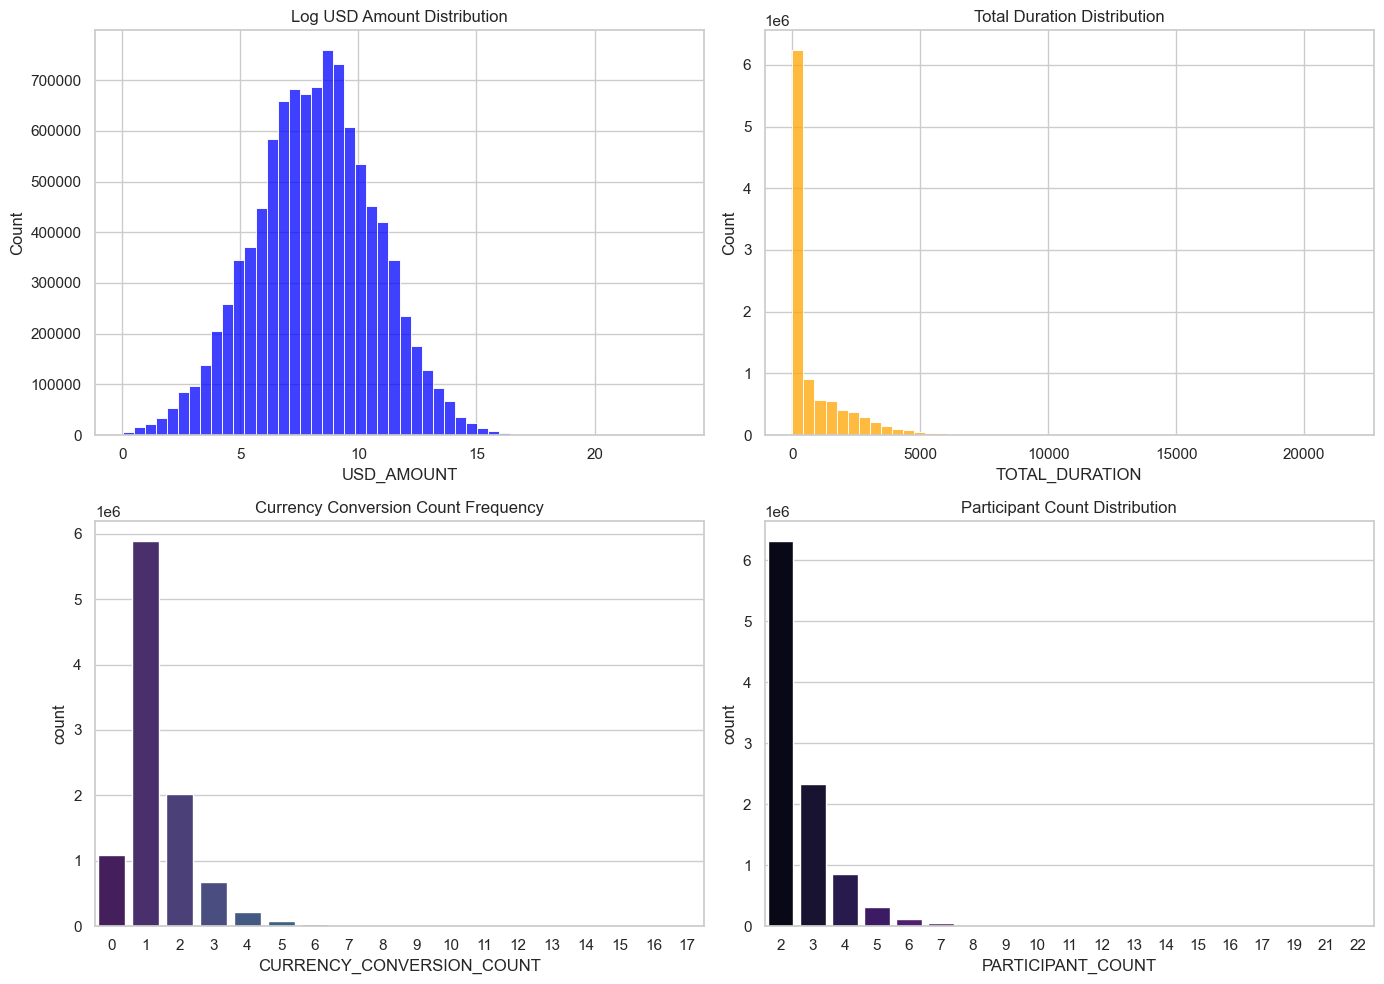

In [5]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Univariate plots for numeric columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. USD Amount (Log scale)
sns.histplot(df['LOG_USD_AMOUNT'] if 'LOG_USD_AMOUNT' in df.columns else np.log1p(df['USD_AMOUNT']), 
             bins=50, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Log USD Amount Distribution')

# 2. Total Duration
sns.histplot(df['TOTAL_DURATION'], bins=50, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Total Duration Distribution')

# 3. Currency Conversion Count
sns.countplot(x='CURRENCY_CONVERSION_COUNT', data=df, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Currency Conversion Count Frequency')

# 4. Participant Count (if available) or Boxplot of Log USD Amount
if 'PARTICIPANT_COUNT' in df.columns:
    sns.countplot(x='PARTICIPANT_COUNT', data=df, ax=axes[1, 1], palette='magma')
    axes[1, 1].set_title('Participant Count Distribution')
else:
    sns.boxplot(x=df['USD_AMOUNT'], ax=axes[1, 1], color='green')
    axes[1, 1].set_title('USD Amount Boxplot')

plt.tight_layout()
plt.show()

# Bivariate Analysis & Currency Anomaly Breakdown

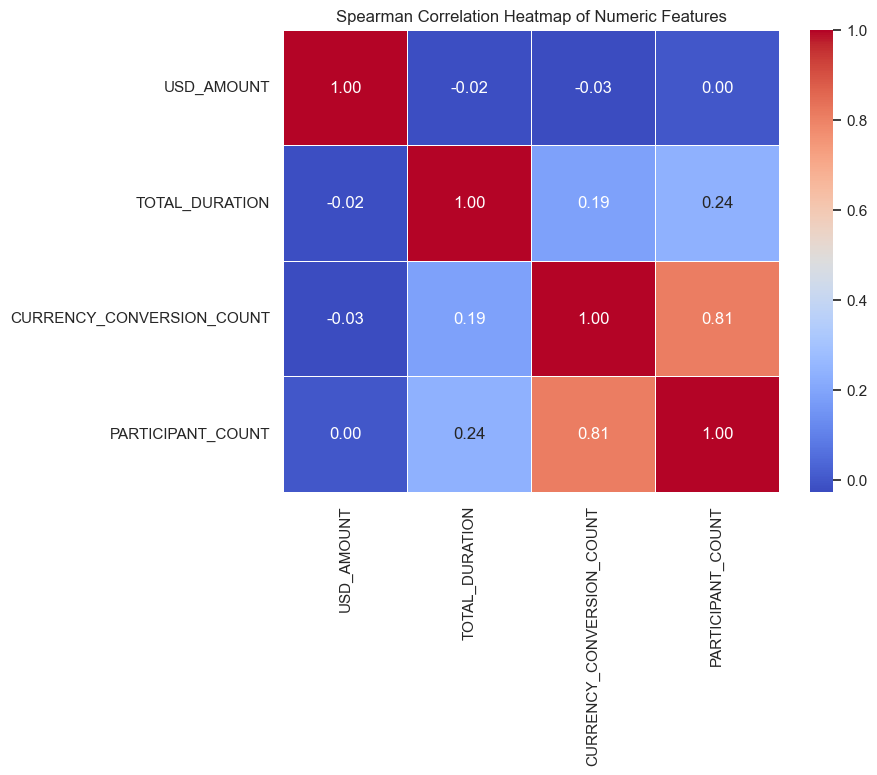


--- Anomaly Type Percentage by Currency Code ---
ANOMALY_TYPE   ACCOUNT_REPLACEMENT_SCAM  CEO_SCAM  CUSTOMER_RECALL  \
CURRENCY_CODE                                                        
AED                                   0         0                0   
AFN                                   0         0                0   
ALL                                   0         0                0   
AMD                                   0         0                0   
ANG                                   0         0                0   
AOA                                   0         0                0   
ARS                                   0         0                0   
AUD                                   0         0                0   
AWG                                   0         0                0   
AZN                                   0         0                0   

ANOMALY_TYPE   DUPLICATE_PAYMENT  FAT_FINGER_MISTAKE  Normal  ROMANCE_SCAM  
CURRENCY_CODE                   

In [6]:
# Bivariate Analysis: Spearman Correlation Matrix & Heatmap
plt.figure(figsize=(8, 6))
numeric_subset = df[['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT', 'PARTICIPANT_COUNT']]
corr_matrix = numeric_subset.corr(method='spearman')

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Spearman Correlation Heatmap of Numeric Features')
plt.show()

# Quick cross-tab / anomaly rate look by Currency Code
if 'CURRENCY_CODE' in df.columns and 'ANOMALY_TYPE' in df.columns:
    anomaly_by_curr = pd.crosstab(df['CURRENCY_CODE'], df['ANOMALY_TYPE'], normalize='index') * 100
    print("\n--- Anomaly Type Percentage by Currency Code ---")
    print(anomaly_by_curr.head(10))

    # Show raw counts instead of normalized percentages
anomaly_by_curr = pd.crosstab(df['CURRENCY_CODE'], df['ANOMALY_TYPE'])
print(anomaly_by_curr.head(15))

# Reverse-Engineering with a Decision Tree

In [7]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import LabelEncoder

# Prepare data for the decision tree (predicting anomaly vs normal, or specific anomaly types)
# Let's create a binary target first: Is it an anomaly or normal?
df['is_anomaly'] = df['ANOMALY_TYPE'] != 'Normal'

# Select features for the tree
feature_cols = ['USD_AMOUNT', 'TOTAL_DURATION', 'CURRENCY_CONVERSION_COUNT', 'PARTICIPANT_COUNT', 'hour']
X = df[feature_cols]
y = df['is_anomaly']

# Train a shallow decision tree (depth 4)
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X, y)

# Print the rules learned by the tree
tree_rules = export_text(tree, feature_names=feature_cols)
print("--- Decision Tree Rules for Predicting Anomalies ---")
print(tree_rules)

--- Decision Tree Rules for Predicting Anomalies ---
|--- USD_AMOUNT <= 119195292.00
|   |--- USD_AMOUNT <= 52247776.00
|   |   |--- USD_AMOUNT <= 4935574.75
|   |   |   |--- USD_AMOUNT <= 0.84
|   |   |   |   |--- class: False
|   |   |   |--- USD_AMOUNT >  0.84
|   |   |   |   |--- class: False
|   |   |--- USD_AMOUNT >  4935574.75
|   |   |   |--- USD_AMOUNT <= 14220759.00
|   |   |   |   |--- class: False
|   |   |   |--- USD_AMOUNT >  14220759.00
|   |   |   |   |--- class: False
|   |--- USD_AMOUNT >  52247776.00
|   |   |--- USD_AMOUNT <= 70201624.00
|   |   |   |--- USD_AMOUNT <= 52867008.00
|   |   |   |   |--- class: False
|   |   |   |--- USD_AMOUNT >  52867008.00
|   |   |   |   |--- class: False
|   |   |--- USD_AMOUNT >  70201624.00
|   |   |   |--- USD_AMOUNT <= 71537516.00
|   |   |   |   |--- class: True
|   |   |   |--- USD_AMOUNT >  71537516.00
|   |   |   |   |--- class: False
|--- USD_AMOUNT >  119195292.00
|   |--- USD_AMOUNT <= 247699672.00
|   |   |--- TOTAL_DUR

# Feature Engineering

In [8]:
# Feature Engineering steps
# 1. Path Length (counting nodes separated by semicolon in BIC8_PATH)
df['path_length'] = df['BIC8_PATH'].astype(str).str.count(';') + 1

# 2. Path length minus participant count discrepancy check
df['path_participant_diff'] = df['path_length'] - df['PARTICIPANT_COUNT']

# 3. Amount per hop
df['amount_per_hop'] = df['USD_AMOUNT'] / df['path_length']

# 4. Same country check (BIC characters 5 and 6 represent the country code)
# Extract country codes if BIC8 is at least 6 characters long
df['ordering_country'] = df['ORDERING_BIC8'].str[4:6]
df['beneficiary_country'] = df['BENEFICIARY_BIC8'].str[4:6]
df['is_same_country'] = df['ordering_country'] == df['beneficiary_country']

print("Feature engineering complete!")
print(df[['USD_AMOUNT', 'path_length', 'PARTICIPANT_COUNT', 'amount_per_hop', 'is_same_country']].head())

Feature engineering complete!
   USD_AMOUNT  path_length  PARTICIPANT_COUNT  amount_per_hop  is_same_country
0         500            2                  2             250             True
1        1390            2                  2             695            False
2        3972            2                  2            1986            False
3        1921            3                  3             640            False
4       22131            2                  2           11065            False


# Engineered Feature Analysis (Country & Amount per Hop)

In [9]:
# Analyze anomaly rates using our newly engineered features
print("--- Anomaly Rate by Same Country Status ---")
print(pd.crosstab(df['is_same_country'], df['ANOMALY_TYPE'], normalize='index') * 100)

print("\n--- Summary Statistics of Amount Per Hop by Anomaly Type ---")
print(df.groupby('ANOMALY_TYPE')['amount_per_hop'].agg(['mean', 'median', 'std']))

# Show raw transaction counts instead of percentages
print(pd.crosstab(df['is_same_country'], df['ANOMALY_TYPE']))

--- Anomaly Rate by Same Country Status ---
ANOMALY_TYPE     ACCOUNT_REPLACEMENT_SCAM  CEO_SCAM  CUSTOMER_RECALL  \
is_same_country                                                        
False                                   0         0                0   
True                                    0         0                0   

ANOMALY_TYPE     DUPLICATE_PAYMENT  FAT_FINGER_MISTAKE  Normal  ROMANCE_SCAM  
is_same_country                                                               
False                            0                   0     100             0  
True                             0                   0     100             0  

--- Summary Statistics of Amount Per Hop by Anomaly Type ---
                             mean  median       std
ANOMALY_TYPE                                       
ACCOUNT_REPLACEMENT_SCAM    25801    1555    150070
CEO_SCAM                   577346    7831   2173880
CUSTOMER_RECALL             36825    1171    251859
DUPLICATE_PAYMENT           6